## Importar librerías y definir el entorno




In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt

FILAS = 4
COLUMNAS = 12
INICIO = (3, 0)
META = (3, 11)
ACANTILADO = {(3, c) for c in range(1, 11)}
ACCIONES = ['N', 'E', 'S', 'W']
MOVIMIENTOS = {'N': (-1, 0), 'E': (0, 1), 'S': (1, 0), 'W': (0, -1)}
ALPHA = 0.5
GAMMA = 1.0
EPSILON = 0.1
EPISODIOS = 500
MAX_PASOS = 200
SEMILLA = 1

ESTADOS = [(r, c) for r in range(FILAS) for c in range(COLUMNAS)
           if (r, c) != META and (r, c) not in ACANTILADO]

print('Tamaño:', FILAS, 'x', COLUMNAS)
print('Estados no terminales:', len(ESTADOS))
print('Inicio:', INICIO, '| Meta:', META, '| Acantilado: columnas 1 a 10 de la última fila')
print('Semilla:', SEMILLA)


Tamaño: 4 x 12
Estados no terminales: 37
Inicio: (3, 0) | Meta: (3, 11) | Acantilado: columnas 1 a 10 de la última fila
Semilla: 1


## Mostrar el entorno

`S` es el inicio, `G` es la meta y `C` representa las casillas del acantilado.


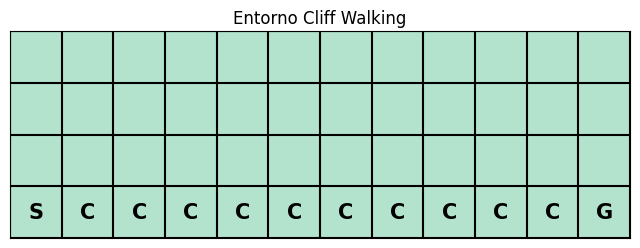

In [2]:
def dibujar_entorno():
    tablero = np.zeros((FILAS, COLUMNAS))
    fig, ax = plt.subplots(figsize=(8, 3))
    ax.imshow(tablero, cmap='Pastel2', vmin=0, vmax=1)
    for r in range(FILAS):
        for c in range(COLUMNAS):
            estado = (r, c)
            texto = ''
            if estado == INICIO:
                texto = 'S'
            elif estado == META:
                texto = 'G'
            elif estado in ACANTILADO:
                texto = 'C'
            ax.text(c, r, texto, ha='center', va='center', fontsize=15, fontweight='bold')
    ax.set_xticks(range(COLUMNAS))
    ax.set_yticks(range(FILAS))
    ax.set_xticks(np.arange(-.5, COLUMNAS, 1), minor=True)
    ax.set_yticks(np.arange(-.5, FILAS, 1), minor=True)
    ax.grid(which='minor', color='black', linewidth=1.5)
    ax.tick_params(which='both', bottom=False, left=False, labelbottom=False, labelleft=False)
    ax.set_title('Entorno Cliff Walking')
    plt.show()

dibujar_entorno()

##  Funciones de transición y política ε-greedy



In [3]:
def transicion(estado, accion):
    dr, dc = MOVIMIENTOS[accion]
    r, c = estado
    nr, nc = r + dr, c + dc
    if nr < 0 or nr >= FILAS or nc < 0 or nc >= COLUMNAS:
        nr, nc = r, c
    siguiente = (nr, nc)

    if siguiente in ACANTILADO:
        # Penaliza la caída y devuelve al agente al inicio.
        # No termina el episodio: el estado siguiente es INICIO.
        return INICIO, -100, False
    if siguiente == META:
        return META, -1, True
    return siguiente, -1, False


def elegir_accion(Q, estado, epsilon, rng):
    if rng.random() < epsilon:
        return rng.choice(ACCIONES)
    valores = [Q[estado][a] for a in ACCIONES]
    maximo = max(valores)
    mejores = [a for a in ACCIONES if Q[estado][a] == maximo]
    return rng.choice(mejores)


## Entrenar el agente con Q-learning




In [4]:
def entrenar(episodios=EPISODIOS, alpha=ALPHA, gamma=GAMMA,
             epsilon=EPSILON, semilla=SEMILLA):
    rng = random.Random(semilla)
    Q = {s: {a: 0.0 for a in ACCIONES} for s in ESTADOS}
    retornos = []

    for episodio in range(episodios):
        estado = INICIO
        retorno = 0
        for paso in range(MAX_PASOS):
            accion = elegir_accion(Q, estado, epsilon, rng)
            siguiente, recompensa, terminado = transicion(estado, accion)
            if terminado:
                futuro = 0
            else:
                futuro = max(Q[siguiente].values())
            objetivo = recompensa + gamma * futuro
            Q[estado][accion] += alpha * (objetivo - Q[estado][accion])
            retorno += recompensa
            estado = siguiente
            if terminado:
                break
        retornos.append(retorno)
    return Q, retornos

Q, retornos = entrenar()
print('Entrenamiento terminado.')
print('Episodios:', len(retornos))
print('Retorno promedio de los últimos 50 episodios:', round(float(np.mean(retornos[-50:])), 2))
print('Mejor retorno observado:', max(retornos))


Entrenamiento terminado.
Episodios: 500
Retorno promedio de los últimos 50 episodios: -68.76
Mejor retorno observado: -13


## Mostrar la tabla Q

Cada fila representa un estado y cada columna una acción. Los valores Q estiman qué tan conveniente es ejecutar una acción desde ese estado.

In [5]:
print(f"{'Estado':<10} {'N':>10} {'E':>10} {'S':>10} {'W':>10}")
print('-' * 54)
for estado in ESTADOS:
    print(f'{str(estado):<10} ' + ' '.join(f'{Q[estado][a]:10.2f}' for a in ACCIONES))

Estado              N          E          S          W
------------------------------------------------------
(0, 0)         -12.69     -12.56     -12.92     -12.81
(0, 1)         -11.81     -11.84     -11.97     -12.43
(0, 2)         -11.12     -11.21     -11.44     -11.33
(0, 3)         -10.71     -10.39     -10.56     -10.75
(0, 4)          -9.57      -9.55      -9.73      -9.48
(0, 5)          -9.06      -8.66      -8.82      -9.42
(0, 6)          -7.94      -7.76      -7.81      -8.47
(0, 7)          -7.00      -6.86      -6.82      -7.66
(0, 8)          -6.38      -5.94      -5.92      -5.95
(0, 9)          -5.00      -4.97      -4.96      -5.86
(0, 10)         -4.00      -3.99      -3.99      -4.29
(0, 11)         -3.00      -3.00      -3.00      -4.06
(1, 0)         -13.02     -12.98     -12.99     -13.24
(1, 1)         -12.08     -12.00     -12.00     -12.74
(1, 2)         -11.87     -11.00     -11.00     -12.36
(1, 3)         -10.71     -10.00     -10.00     -11.60
(1, 4)    

##  Visualizar la política aprendida

Las flechas muestran la acción con mayor valor Q en cada casilla. Se marca `S`, `G` y `C` para identificar inicio, meta y acantilado.

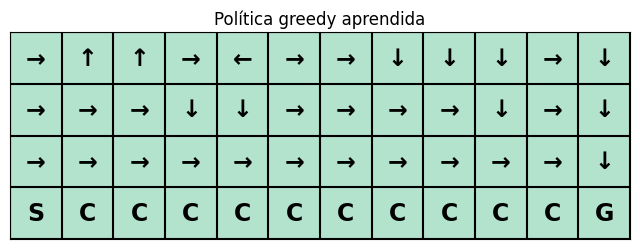

In [6]:
FLECHAS = {'N': '↑', 'E': '→', 'S': '↓', 'W': '←'}

def dibujar_politica(Q):
    fig, ax = plt.subplots(figsize=(8, 3))
    ax.imshow(np.zeros((FILAS, COLUMNAS)), cmap='Pastel2', vmin=0, vmax=1)
    for r in range(FILAS):
        for c in range(COLUMNAS):
            estado = (r, c)
            if estado == INICIO:
                texto = 'S'
            elif estado == META:
                texto = 'G'
            elif estado in ACANTILADO:
                texto = 'C'
            else:
                mejores = max(Q[estado], key=Q[estado].get)
                texto = FLECHAS[mejores]
            ax.text(c, r, texto, ha='center', va='center', fontsize=17, fontweight='bold')
    ax.set_xticks(np.arange(-.5, COLUMNAS, 1), minor=True)
    ax.set_yticks(np.arange(-.5, FILAS, 1), minor=True)
    ax.grid(which='minor', color='black', linewidth=1.5)
    ax.tick_params(which='both', bottom=False, left=False, labelbottom=False, labelleft=False)
    ax.set_title('Política greedy aprendida')
    plt.show()

dibujar_politica(Q)

### Retorno greedy y camino aprendido

Se evalúa la política aprendida sin exploración aleatoria. En caso de empate entre acciones, se toma la primera según el orden N, E, S, W.

In [7]:
def evaluar_greedy(Q):
    estado = INICIO
    retorno_greedy = 0
    camino = [estado]
    for paso in range(MAX_PASOS):
        valores = [Q[estado][a] for a in ACCIONES]
        accion = ACCIONES[valores.index(max(valores))]
        siguiente, recompensa, terminado = transicion(estado, accion)
        retorno_greedy += recompensa
        estado = siguiente
        camino.append(estado)
        if terminado:
            print("Retorno greedy:", retorno_greedy)
            print("Pasos hasta la meta:", paso + 1)
            print("Camino greedy (fila, columna):")
            print(" -> ".join(str(s) for s in camino))
            return retorno_greedy, camino
    print("La política greedy no llegó a la meta dentro del límite de pasos.")
    print("Retorno acumulado:", retorno_greedy)
    print("Camino recorrido:", camino)
    return retorno_greedy, camino

retorno_greedy, camino_greedy = evaluar_greedy(Q)


Retorno greedy: -13
Pasos hasta la meta: 13
Camino greedy (fila, columna):
(3, 0) -> (2, 0) -> (2, 1) -> (2, 2) -> (2, 3) -> (2, 4) -> (2, 5) -> (2, 6) -> (2, 7) -> (2, 8) -> (2, 9) -> (2, 10) -> (2, 11) -> (3, 11)


## Curva de aprendizaje

El retorno es la suma de recompensas recibidas en un episodio. Como cada paso normal tiene recompensa −1 y el acantilado penaliza con −100, un retorno menos negativo suele indicar una ruta más corta y segura.

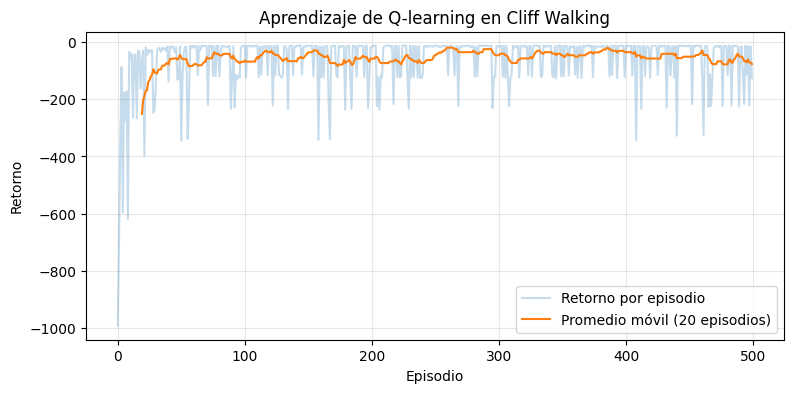

In [8]:
def promedio_movil(valores, ventana=20):
    return np.convolve(valores, np.ones(ventana) / ventana, mode='valid')

plt.figure(figsize=(9, 4))
plt.plot(retornos, alpha=0.25, label='Retorno por episodio')
plt.plot(range(19, len(retornos)), promedio_movil(retornos, 20), label='Promedio móvil (20 episodios)')
plt.xlabel('Episodio')
plt.ylabel('Retorno')
plt.title('Aprendizaje de Q-learning en Cliff Walking')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Experimentos con parámetros



Experimento           Retorno promedio (últimos 50)
----------------------------------------------------
Base                                         -68.76
Alpha = 0.1                                  -49.02
Gamma = 0.8                                  -64.72
Epsilon = 0.3                               -200.02


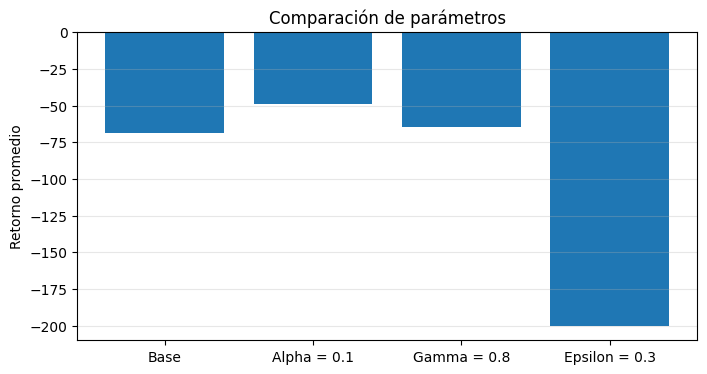

In [9]:
experimentos = [
    ('Base', ALPHA, GAMMA, EPSILON),
    ('Alpha = 0.1', 0.1, GAMMA, EPSILON),
    ('Gamma = 0.8', ALPHA, 0.8, EPSILON),
    ('Epsilon = 0.3', ALPHA, GAMMA, 0.3),
]
resultados = []
for nombre, alpha, gamma, epsilon in experimentos:
    q_exp, ret_exp = entrenar(episodios=EPISODIOS, alpha=alpha, gamma=gamma,
                              epsilon=epsilon, semilla=SEMILLA)
    resultados.append((nombre, round(float(np.mean(ret_exp[-50:])), 2)))

print(f"{'Experimento':<20} {'Retorno promedio (últimos 50)':>30}")
print('-' * 52)
for nombre, promedio in resultados:
    print(f'{nombre:<20} {promedio:>30.2f}')

plt.figure(figsize=(8, 4))
plt.bar([x[0] for x in resultados], [x[1] for x in resultados])
plt.ylabel('Retorno promedio')
plt.title('Comparación de parámetros')
plt.grid(axis='y', alpha=0.3)
plt.show()